# **2. Mapa Semântico dos Motivos de Cartão**

Responsabilidade deste notebook:

- carregar `data/processed/card_reasons_long.csv`;
- transformar os motivos limpos em embeddings com modelo PT-BR;
- opcionalmente fazer fine-tuning com pares extraídos das próprias súmulas;
- clusterizar com HDBSCAN (ou KMeans) sobre redução UMAP intermediária;
- projetar o mapa semântico em 2D;
- gerar tabelas de interpretação por cluster, ano, time e árbitro.

## **1. Configuração**

In [70]:
import re
import unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
import umap
from sentence_transformers import SentenceTransformer
from sentence_transformers import models as st_models
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 180)
plt.style.use("seaborn-v0_8-whitegrid")


In [71]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROCESSED_PATH / "semantic_card_reasons"

CARD_REASONS_LONG_PATH = PROCESSED_PATH / "card_reasons_long.csv"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

# --- Modelo de embedding ---
# Troque MODEL_NAME para experimentar:
#   "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"  (padrão — mais preciso que MiniLM)
#   "neuralmind/bert-base-portuguese-cased"                        (BERTimbau — específico para PT-BR)
#   "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"  (original — mais rápido)
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"

# --- Fine-tuning com dados do domínio ---
# True: gera pares positivos das súmulas e treina com MultipleNegativesRankingLoss.
# Na segunda execução carrega o modelo salvo sem re-treinar.
FINETUNE_MODEL = True
FINETUNED_MODEL_DIR = MODELS_DIR / "football_pt_embeddings"

# --- Clusterização ---
# O UMAP intermediário deixa o espaço mais adequado para clusterização fina.
# KMeans continua determinístico; HDBSCAN pode ser testado quando você quiser ruído/outliers.
CLUSTER_METHOD = "kmeans"  # opções: "kmeans" ou "hdbscan"
CLUSTER_FEATURE_SPACE = "umap"  # opções: "umap" ou "embeddings"
UMAP_CLUSTER_COMPONENTS = 15
UMAP_CLUSTER_N_NEIGHBORS = 25
UMAP_CLUSTER_MIN_DIST = 0.0
KMEANS_K_MIN = 8
KMEANS_K_MAX = 35
KMEANS_K_MAX_FACTOR = 2.0
PREFER_GRANULAR_CLUSTERS = True
GRANULAR_SILHOUETTE_TOLERANCE = 0.03
HDBSCAN_MIN_CLUSTER_SIZE = 30
HDBSCAN_MIN_SAMPLES = 10

# Pós-processamento semântico: separa clusters mistos por ações conhecidas do domínio.
APPLY_DOMAIN_SPLIT = True
DOMAIN_SPLIT_MIN_EVENTS = 25
DOMAIN_SPLIT_MIN_SHARE = 0.08
OFFENSE_SPLIT_MIN_EVENTS = 5
OFFENSE_SPLIT_MIN_SHARE = 0.01

# Colunas de texto
TEXT_COLUMN = "reason_detail_key"        # chave de deduplicação/merge (sem acentos)
EMBEDDING_TEXT_COLUMN = "reason_detail"  # texto para embedding (com acentos — melhor para modelos PT)


## **2. Carregamento da Base Limpa**

A entrada é `card_reasons_long.csv` gerada no notebook 1.
A coluna `reason_detail` (com acentos) é usada para embedding; `reason_detail_key` (normalizada) é a chave de deduplicação.

In [72]:
REQUIRED_COLUMNS = {
    "year", "match_date", "home_team", "away_team", "arbitro",
    "card_type", "team", "reason", "reason_key",
    "reason_category", "reason_category_key",
    "reason_detail", "reason_detail_key",
}

reasons = pd.read_csv(CARD_REASONS_LONG_PATH)
missing = REQUIRED_COLUMNS.difference(reasons.columns)
if missing:
    raise ValueError(f"Colunas ausentes em card_reasons_long.csv: {sorted(missing)}")

reasons[TEXT_COLUMN] = reasons[TEXT_COLUMN].fillna("").astype(str).str.strip()
reasons = reasons[reasons[TEXT_COLUMN].ne("")].reset_index(drop=True)
reasons.head()

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key,reason_category,reason_category_key,reason_detail,reason_detail_key
0,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamar ostensivamente com palavras e gestos.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem. - por reclamar ostensivamente com palavras e gestos.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem.,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.
1,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,37,1T,Cometer uma falta tática para impedir um ataque promissor - Calçar o adversário disputando a bola e impedir um ataque promissor .,cometer uma falta tatica para impedir um ataque promissor - calcar o adversario disputando a bola e impedir um ataque promissor .,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Calçar o adversário disputando a bola e impedir um ataque promissor .,calcar o adversario disputando a bola e impedir um ataque promissor .
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,18,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de maneira temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar um calco em seu adversario na disputa pela bola de maneira temeraria.
3,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,28,2T,"Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser) - Por cometer uma atitude antidesportiva fora da disputa pela bola.","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser) - por cometer uma atitude antidesportiva fora da disputa pela bola.","Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser)","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser)",Por cometer uma atitude antidesportiva fora da disputa pela bola.,por cometer uma atitude antidesportiva fora da disputa pela bola.
4,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,28,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de forma temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar um calco em seu adversario na disputa pela bola de forma temeraria.


## **3. Preparação dos Textos para Embedding**

Os embeddings são calculados sobre textos únicos de `reason_detail_key` (chave de deduplicação),
mas o texto real enviado ao modelo é `reason_detail` (com acentos), que produz representações
melhores com modelos treinados em português.
Quando `reason_detail` está vazio, faz fallback para `reason_category`.

In [73]:
reason_counts = reasons.groupby(TEXT_COLUMN).agg(
    reason=("reason", "first"),
    reason_category=("reason_category", "first"),
    reason_category_key=("reason_category_key", "first"),
    reason_detail=("reason_detail", "first"),
    n_events=("reason", "size"),
    n_yellow=("card_type", lambda values: (values == "yellow").sum()),
    n_red=("card_type", lambda values: (values == "red").sum()),
).reset_index().rename(columns={TEXT_COLUMN: "embedding_key"})

# Usa reason_detail (com acentos) para embedding; fallback para reason_category se vazio
reason_counts["text_for_embedding"] = (
    reason_counts[EMBEDDING_TEXT_COLUMN]
    .fillna("")
    .str.strip()
    .where(lambda s: s != "", other=reason_counts["reason_category"])
)

reason_counts = reason_counts.sort_values("n_events", ascending=False).reset_index(drop=True)
reason_counts.head(15)

,embedding_key,reason,reason_category,reason_category_key,reason_detail,n_events,n_yellow,n_red,text_for_embedding
0,por calcar seu adversario de maneira temeraria na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por calçar seu adversário de maneira temerária na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Por calçar seu adversário de maneira temerária na disputa de bola.,238,238,0,Por calçar seu adversário de maneira temerária na disputa de bola.
1,por cometer uma falta tatica impedindo um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor - Por cometer uma falta tática impedindo um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática impedindo um ataque promissor.,154,154,0,Por cometer uma falta tática impedindo um ataque promissor.
2,cometer uma falta tatica para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor - Cometer uma falta tática para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,125,124,1,Cometer uma falta tática para impedir um ataque promissor.
3,por retardar o reinicio de jogo.,Retardar o reinício do jogo - Por retardar o reinício de jogo.,Retardar o reinício do jogo,retardar o reinicio do jogo,Por retardar o reinício de jogo.,122,122,0,Por retardar o reinício de jogo.
4,por cometer uma falta tatica para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor - Por cometer uma falta tática para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,115,115,0,Por cometer uma falta tática para impedir um ataque promissor.
5,dar uma entrada contra um adversario de maneira temeraria na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola - Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,104,103,1,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.
6,por dar uma entrada contra seu adversario de maneira temeraria na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola - Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.,103,103,0,Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.
7,por calcar seu adversario de forma temeraria na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por calçar seu adversário de forma temerária na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Por calçar seu adversário de forma temerária na disputa de bola.,91,91,0,Por calçar seu adversário de forma temerária na disputa de bola.
8,dar uma entrada contra um adversario de maneira temeraria na disputa de b

## **4. Modelo de Embedding**

Suporta qualquer modelo `sentence-transformers` nativo ou BERT puro (ex: `neuralmind/bert-base-portuguese-cased`)
via wrapper de mean pooling.

In [74]:
def load_embedding_model(model_name_or_path) -> SentenceTransformer:
    """Carrega modelo sentence-transformers ou BERT puro com mean pooling."""
    path = str(model_name_or_path)
    try:
        model = SentenceTransformer(path)
        print(f"[OK] Carregado via SentenceTransformer: {path}")
        return model
    except Exception:
        # Fallback: BERT puro + mean pooling (ex: neuralmind/bert-base-portuguese-cased)
        word_model = st_models.Transformer(path, max_seq_length=256)
        pooling = st_models.Pooling(
            word_model.get_word_embedding_dimension(),
            pooling_mode_mean_tokens=True,
        )
        model = SentenceTransformer(modules=[word_model, pooling])
        print(f"[OK] Carregado como BERT + mean pooling: {path}")
        return model


INITIAL_MODEL_PATH = (
    FINETUNED_MODEL_DIR
    if FINETUNE_MODEL and (FINETUNED_MODEL_DIR / "modules.json").exists()
    else MODEL_NAME
)
embedding_model = load_embedding_model(INITIAL_MODEL_PATH)
print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8115.14it/s]


[OK] Carregado via SentenceTransformer: /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_pt_embeddings
Dimensão dos embeddings: 768


/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_76842/4246155329.py:26: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")


In [75]:
texts = reason_counts["text_for_embedding"].tolist()
print(f"Textos únicos para embedding: {len(texts):,}")


Textos únicos para embedding: 4,657


## **5. Fine-Tuning com Dados do Domínio**

Gera pares positivos diretamente das súmulas:
- `(reason_category, reason_detail)` de um mesmo cartão — sempre semanticamente próximos;
- `(detail_i, detail_j)` dentro da mesma `reason_category_key` — variações textuais da mesma infração.

Treina com `MultipleNegativesRankingLoss`: cada frase do batch serve como negativo das outras.
Na segunda execução carrega o modelo salvo sem re-treinar.

Se `FINETUNE_MODEL = False`, esta célula é ignorada.

In [76]:
if FINETUNE_MODEL:
    # modules.json é criado apenas ao final de um ft_model.save() completo
    _model_ready = (FINETUNED_MODEL_DIR / "modules.json").exists()

    if _model_ready:
        if Path(INITIAL_MODEL_PATH) == FINETUNED_MODEL_DIR:
            print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Usando modelo já carregado.")
        else:
            print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Carregando...")
            embedding_model = load_embedding_model(FINETUNED_MODEL_DIR)
    else:
        # Remove diretório incompleto de runs anteriores que falharam
        import shutil
        if FINETUNED_MODEL_DIR.exists():
            shutil.rmtree(FINETUNED_MODEL_DIR)

        # Instala datasets (HuggingFace) se não estiver disponível
        try:
            import datasets as hf_datasets
        except ImportError:
            import subprocess, sys
            print("Instalando datasets...")
            subprocess.check_call([sys.executable, "-m", "pip", "install", "datasets", "-q"])
            import datasets as hf_datasets

        from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
        from sentence_transformers.losses import MultipleNegativesRankingLoss
        from sentence_transformers.training_args import BatchSamplers

        # Workaround: bug no sentence-transformers 5.5.0 — IterableDataset não importado em base/trainer.py
        import sentence_transformers.base.trainer as _st_base_trainer
        if not hasattr(_st_base_trainer, "IterableDataset"):
            from torch.utils.data import IterableDataset as _IterableDataset
            _st_base_trainer.IterableDataset = _IterableDataset

        # Geração de pares positivos
        positive_pairs = []
        for cat_key, group in reasons.groupby("reason_category_key"):
            details = (
                group["reason_detail"]
                .dropna()
                .str.strip()
                .pipe(lambda s: s[s != ""])
                .unique()
                .tolist()
            )
            categories = group["reason_category"].dropna().unique().tolist()

            # (categoria padronizada, descrição livre do árbitro)
            for cat in categories[:1]:
                for det in details[:12]:
                    positive_pairs.append({"anchor": cat, "positive": det})

            # (descrição_i, descrição_j) — mesma infração, texto diferente
            sample = details[:12]
            for i in range(len(sample)):
                for j in range(i + 1, len(sample)):
                    positive_pairs.append({"anchor": sample[i], "positive": sample[j]})

        print(f"Pares positivos gerados: {len(positive_pairs):,}")
        train_dataset = hf_datasets.Dataset.from_list(positive_pairs)

        # Treino — forçado em CPU para evitar OOM no MPS (Apple Silicon)
        # Com ~2600 pares e 3 épocas, leva ~5-10 min na CPU
        ft_model = load_embedding_model(MODEL_NAME)
        train_loss = MultipleNegativesRankingLoss(ft_model)

        training_args = SentenceTransformerTrainingArguments(
            output_dir=str(FINETUNED_MODEL_DIR / "checkpoints"),
            num_train_epochs=3,
            per_device_train_batch_size=32,
            learning_rate=2e-5,
            warmup_steps=0.1,
            fp16=False,
            use_cpu=True,           # evita OOM no MPS; CPU é suficiente para este dataset
            batch_sampler=BatchSamplers.NO_DUPLICATES,
            save_strategy="no",
            logging_steps=50,
        )

        trainer = SentenceTransformerTrainer(
            model=ft_model,
            args=training_args,
            train_dataset=train_dataset,
            loss=train_loss,
        )
        trainer.train()

        ft_model.save(str(FINETUNED_MODEL_DIR))
        print(f"Modelo salvo em: {FINETUNED_MODEL_DIR}")
        embedding_model = ft_model


else:
    print("Fine-tuning desabilitado (FINETUNE_MODEL=False). Usando embeddings do modelo base.")

Modelo fine-tunado encontrado em /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_pt_embeddings. Usando modelo já carregado.


## **5.1. Cálculo dos Embeddings Finais**

In [77]:
embeddings = embedding_model.encode(
    texts,
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
embeddings = np.asarray(embeddings)
print(f"Embeddings computados com o modelo final. Shape: {embeddings.shape}")


Batches: 100%|██████████| 73/73 [00:07<00:00,  9.80it/s]

Embeddings computados com o modelo final. Shape: (4657, 768)


## **6. Clusterização**

A clusterização usa uma projeção UMAP intermediária para deixar vizinhos semânticos mais próximos antes do agrupamento. No modo `kmeans`, o notebook avalia vários `k`, mas pode preferir o maior `k` dentro de uma tolerância de silhouette para produzir clusters mais específicos. O agrupamento macro interpretável é criado depois, sem perder esses clusters finos.


/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Textos únicos: 4,657 | espaço de clusterização: UMAP-15D
Buscando k em [8, 35]


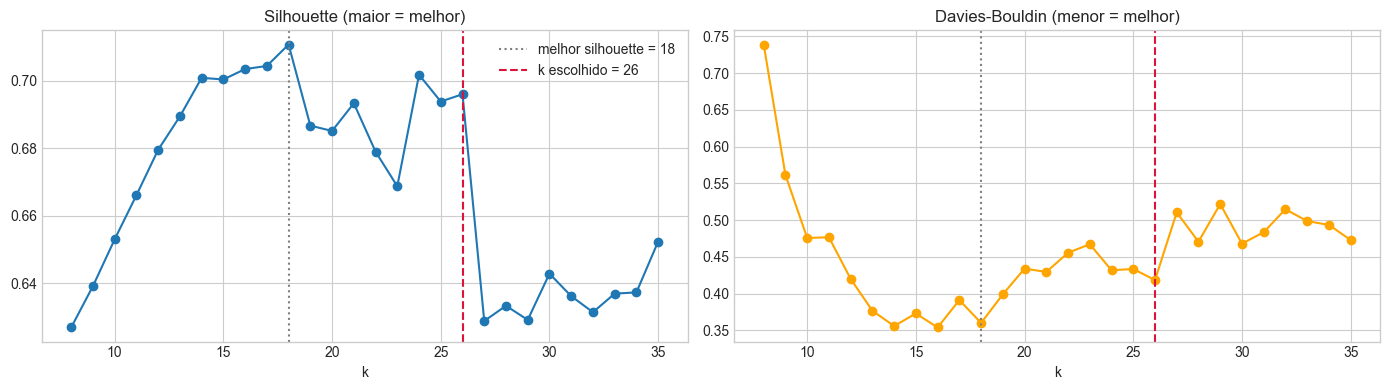

k com maior silhouette: 18 (silhouette=0.7108)
k escolhido por granularidade: 26 (dentro de 0.03 do melhor silhouette)
Avaliação: Silhouette = 0.6961 | Davies-Bouldin = 0.4184 | ruído = 0.0%
(Silhouette: maior melhor | Davies-Bouldin: menor melhor)


In [78]:
n_unique = len(reason_counts)

if CLUSTER_FEATURE_SPACE == "umap" and n_unique > 3:
    n_components_cluster = min(UMAP_CLUSTER_COMPONENTS, max(2, n_unique - 2))
    n_neighbors_cluster = min(UMAP_CLUSTER_N_NEIGHBORS, n_unique - 1)
    cluster_reducer = umap.UMAP(
        n_components=n_components_cluster,
        n_neighbors=n_neighbors_cluster,
        min_dist=UMAP_CLUSTER_MIN_DIST,
        metric="cosine",
        random_state=RANDOM_STATE,
    )
    cluster_features = cluster_reducer.fit_transform(embeddings)
    cluster_metric = "euclidean"
    cluster_space_label = f"UMAP-{n_components_cluster}D"
else:
    cluster_features = embeddings
    cluster_metric = "cosine"
    cluster_space_label = "embeddings"

print(f"Textos únicos: {n_unique:,} | espaço de clusterização: {cluster_space_label}")


def evaluate_clustering(features: np.ndarray, labels: np.ndarray, metric: str) -> dict:
    labels = np.asarray(labels)
    valid_mask = labels != -1
    valid_labels = labels[valid_mask]
    n_clusters = len(set(valid_labels))
    noise_share = float((labels == -1).mean())

    if n_clusters < 2 or valid_mask.sum() <= n_clusters:
        return {
            "n_clusters": n_clusters,
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "noise_share": noise_share,
        }

    valid_features = features[valid_mask]
    return {
        "n_clusters": n_clusters,
        "silhouette": silhouette_score(valid_features, valid_labels, metric=metric),
        "davies_bouldin": davies_bouldin_score(valid_features, valid_labels),
        "noise_share": noise_share,
    }


if CLUSTER_METHOD == "kmeans":
    k_min = max(2, min(KMEANS_K_MIN, n_unique - 1))
    auto_k_max = int(np.sqrt(n_unique) * KMEANS_K_MAX_FACTOR)
    k_max = min(KMEANS_K_MAX, max(k_min, auto_k_max), n_unique - 1)
    candidate_ks = list(range(k_min, k_max + 1))

    print(f"Buscando k em [{k_min}, {k_max}]")
    scores = []
    for k in candidate_ks:
        labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit_predict(cluster_features)
        row = evaluate_clustering(cluster_features, labels, cluster_metric)
        row["k"] = k
        scores.append(row)

    cluster_scores = pd.DataFrame(scores)
    metric_best_row = cluster_scores.sort_values("silhouette", ascending=False).iloc[0]
    metric_best_k = int(metric_best_row["k"])
    best_silhouette = float(metric_best_row["silhouette"])

    if PREFER_GRANULAR_CLUSTERS:
        eligible = cluster_scores[
            cluster_scores["silhouette"] >= best_silhouette - GRANULAR_SILHOUETTE_TOLERANCE
        ]
        BEST_K = int(eligible.sort_values(["k", "silhouette"], ascending=[False, False]).iloc[0]["k"])
    else:
        BEST_K = metric_best_k

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(cluster_scores["k"], cluster_scores["silhouette"], marker="o")
    axes[0].axvline(metric_best_k, color="gray", linestyle=":", label=f"melhor silhouette = {metric_best_k}")
    axes[0].axvline(BEST_K, color="crimson", linestyle="--", label=f"k escolhido = {BEST_K}")
    axes[0].set_title("Silhouette (maior = melhor)")
    axes[0].set_xlabel("k")
    axes[0].legend()
    axes[1].plot(cluster_scores["k"], cluster_scores["davies_bouldin"], marker="o", color="orange")
    axes[1].axvline(metric_best_k, color="gray", linestyle=":")
    axes[1].axvline(BEST_K, color="crimson", linestyle="--")
    axes[1].set_title("Davies-Bouldin (menor = melhor)")
    axes[1].set_xlabel("k")
    plt.tight_layout()
    plt.show()

    cluster_model = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=50)
    reason_counts["cluster"] = cluster_model.fit_predict(cluster_features)
    selected_eval = evaluate_clustering(cluster_features, reason_counts["cluster"].values, cluster_metric)
    print(f"k com maior silhouette: {metric_best_k} (silhouette={best_silhouette:.4f})")
    if PREFER_GRANULAR_CLUSTERS and BEST_K != metric_best_k:
        print(
            f"k escolhido por granularidade: {BEST_K} "
            f"(dentro de {GRANULAR_SILHOUETTE_TOLERANCE:.2f} do melhor silhouette)"
        )
    else:
        print(f"k escolhido: {BEST_K}")

elif CLUSTER_METHOD == "hdbscan":
    min_cluster_size = min(HDBSCAN_MIN_CLUSTER_SIZE, max(2, n_unique // 2))
    cluster_model = hdbscan.HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=HDBSCAN_MIN_SAMPLES,
        metric="euclidean",
        cluster_selection_method="eom",
    )
    reason_counts["cluster"] = cluster_model.fit_predict(cluster_features)
    selected_eval = evaluate_clustering(cluster_features, reason_counts["cluster"].values, "euclidean")
    BEST_K = selected_eval["n_clusters"]
    print(f"Clusters encontrados pelo HDBSCAN: {BEST_K} | ruído: {selected_eval['noise_share']:.1%}")

else:
    raise ValueError("CLUSTER_METHOD deve ser 'kmeans' ou 'hdbscan'.")

print(
    "Avaliação: "
    f"Silhouette = {selected_eval['silhouette']:.4f} | "
    f"Davies-Bouldin = {selected_eval['davies_bouldin']:.4f} | "
    f"ruído = {selected_eval['noise_share']:.1%}"
)
print("(Silhouette: maior melhor | Davies-Bouldin: menor melhor)")


## **6.1. Ajuste Semântico Fino por Domínio**

Depois do agrupamento vetorial, clusters com mistura clara de ações disciplinares conhecidas são subdivididos por rótulo canônico. Isso mantém a vantagem do embedding, mas evita que `entrada temerária`, `calçar de forma temerária` e `pontapé/chute temerário` virem um único cluster grande.

In [79]:
def normalize_domain_text(text: str) -> str:
    text = "".join(
        char for char in unicodedata.normalize("NFKD", str(text).lower())
        if not unicodedata.combining(char)
    )
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


DIRECT_REFEREE_OFFENSE_PATTERNS = [
    r"\b(?:vai|va|vao)\s+(?:se\s+)?(?:foder|fuder|tomar)\b",
    r"\btomar\s+no\s+cu\b",
    r"\bfilho\s+da\s+puta\b",
    r"\bhijo\s+de\s+puta\b",
    r"\bmerdas?\b",
    r"\bporra\b",
    r"\bcaralho\b",
    r"\bpalhacad[ao]\b",
    r"\bbabaca\b",
    r"\bvagabund[oa]\b",
    r"\bsafad[oa]\b",
    r"\bladra[oa]\b",
    r"\broubou\b",
    r"\broubar\b",
    r"\broubo\b",
    r"\bsem\s+vergonha\b",
    r"\bcovarde\b",
    r"\bmuito\s+fraco\b",
]
DIRECT_REFEREE_OFFENSE_RE = re.compile("|".join(DIRECT_REFEREE_OFFENSE_PATTERNS))

DIRECT_REFEREE_TARGET_TERMS = [
    "arbitro", "arbitragem", "quarto arbitro", "assistente",
    "minha pessoa", "me ofendeu", "me senti ofendido", "em minha direcao",
    "para mim", "pra mim", "decisao da arbitragem", "decisoes da arbitragem",
]
DIRECT_REFEREE_TARGET_TOKENS = {"var", "ara"}
DIRECT_REFEREE_SPEECH_TERMS = ["voce", "voces", "tu", "seu"]
DIRECT_REFEREE_REPORTING_TERMS = [
    "proferiu", "proferindo", "disse", "dizendo", "falou", "gritou",
    "ofendeu", "ofensiva", "ofensivo", "grosseira", "grosseiro",
]
ADVERSARY_CONTEXT_TERMS = [
    "contra seu adversario", "contra o adversario", "contra um adversario",
    "ofensas verbais contra seu adversario", "ofensas contra seu adversario",
]


def has_direct_referee_offense(profile: str) -> bool:
    profile = normalize_domain_text(profile)
    if not DIRECT_REFEREE_OFFENSE_RE.search(profile):
        return False

    tokens = set(profile.split())
    has_target = (
        any(term in profile for term in DIRECT_REFEREE_TARGET_TERMS)
        or bool(tokens & DIRECT_REFEREE_TARGET_TOKENS)
    )
    has_reported_speech = any(term in profile for term in DIRECT_REFEREE_REPORTING_TERMS)
    has_direct_speech = any(term in profile for term in DIRECT_REFEREE_SPEECH_TERMS)
    adversary_only = any(term in profile for term in ADVERSARY_CONTEXT_TERMS) and not has_target

    return not adversary_only and (has_target or (has_reported_speech and has_direct_speech))


def canonical_domain_label(row: pd.Series) -> str | None:
    detail = normalize_domain_text(row.get("embedding_key", ""))
    category = normalize_domain_text(row.get("reason_category_key", ""))
    profile = f"{detail} {category}"

    if has_direct_referee_offense(profile):
        return "Ofensa direta à arbitragem"

    if "ataque promissor" in profile:
        if any(term in detail for term in ["segurar", "agarrar", "puxar", "empurrar"]):
            return "Segurar para impedir ataque promissor"
        return "Impedir ataque promissor"

    if "temeraria" in profile or "temerario" in profile:
        if any(term in detail for term in ["calcar", "calco", "calcado", "rasteira"]):
            return "Calçar de forma temerária"
        if "entrada" in detail:
            return "Entrada temerária"
        if "golpear" in detail:
            return "Golpear de forma temerária"
        if any(term in detail for term in ["pontape", "chute", "tranco", "atingir", "carga"]):
            return "Pontapé/chute temerário"
        if any(term in category for term in ["calcar", "calco", "rasteira"]):
            return "Calçar de forma temerária"
        if "entrada" in category:
            return "Entrada temerária"
        if "golpear" in category:
            return "Golpear de forma temerária"
        if any(term in category for term in ["pontape", "chute"]):
            return "Pontapé/chute temerário"

    if "arbitragem" in profile and any(term in profile for term in ["reclamar", "desaprovar", "protestar"]):
        return "Reclamar/desaprovar decisões da arbitragem"
    if "retardar" in profile and "reinicio" in profile:
        return "Retardar reinício do jogo"
    if "chutar" in profile and "longe" in profile:
        return "Chutar bola para longe"
    if "comemoracao" in profile or ("tirar" in profile and "camisa" in profile):
        return "Comemoração de gol"
    if "infringir persistentemente" in profile:
        return "Infringir persistentemente as regras"
    if "simular" in profile or "simulando" in profile:
        return "Simulação/fingir falta"
    return None


if APPLY_DOMAIN_SPLIT:
    reason_counts["cluster_base"] = reason_counts["cluster"]
    reason_counts["domain_split_label"] = reason_counts.apply(canonical_domain_label, axis=1)
    split_keys = []

    for cluster_id, group in reason_counts.groupby("cluster_base", sort=True):
        event_total = group["n_events"].sum()
        label_events = (
            group.dropna(subset=["domain_split_label"])
            .groupby("domain_split_label")["n_events"]
            .sum()
            .sort_values(ascending=False)
        )
        active_labels = set(
            label_events[
                (label_events >= DOMAIN_SPLIT_MIN_EVENTS)
                & ((label_events / max(event_total, 1)) >= DOMAIN_SPLIT_MIN_SHARE)
            ].index
        )
        offense_events = label_events.get("Ofensa direta à arbitragem", 0)
        if (
            offense_events >= OFFENSE_SPLIT_MIN_EVENTS
            and (offense_events / max(event_total, 1)) >= OFFENSE_SPLIT_MIN_SHARE
        ):
            active_labels.add("Ofensa direta à arbitragem")
        should_split = len(active_labels) >= 2 or "Ofensa direta à arbitragem" in active_labels

        for row_index, row in group.iterrows():
            label = row["domain_split_label"]
            if should_split and label in active_labels:
                split_keys.append((row_index, f"{cluster_id}::{label}"))
            else:
                split_keys.append((row_index, f"{cluster_id}::__base__"))

    split_key_series = pd.Series(dict(split_keys)).sort_index()
    reason_counts["cluster_split_key"] = split_key_series
    reason_counts["cluster"] = pd.factorize(reason_counts["cluster_split_key"], sort=True)[0]
    print(
        f"Clusters após ajuste por domínio: {reason_counts['cluster'].nunique()} "
        f"(antes: {reason_counts['cluster_base'].nunique()})"
    )
else:
    reason_counts["cluster_base"] = reason_counts["cluster"]
    reason_counts["domain_split_label"] = None
    reason_counts["cluster_split_key"] = reason_counts["cluster"].astype(str)


Clusters após ajuste por domínio: 35 (antes: 26)


In [80]:
cluster_assignment_columns = [
    "embedding_key", "cluster", "cluster_base", "domain_split_label", "cluster_split_key",
]

reasons_clustered = reasons.merge(
    reason_counts[cluster_assignment_columns],
    left_on=TEXT_COLUMN,
    right_on="embedding_key",
    how="left",
).drop(columns=["embedding_key"])

print(f"Cartões sem cluster: {reasons_clustered['cluster'].isna().sum()}")
reasons_clustered.head()


Cartões sem cluster: 0


,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,...,reason,reason_key,reason_category,reason_category_key,reason_detail,reason_detail_key,cluster,cluster_base,domain_split_label,cluster_split_key
0,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,...,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamar ostensivamente com palavras e gestos.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem. - por reclamar ostensivamente com palavras e gestos.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem.,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.,15,1,Reclamar/desaprovar decisões da arbitragem,1::__base__
1,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,...,Cometer uma falta tática para impedir um ataque promissor - Calçar o adversário disputando a bola e impedir um ataque promissor .,cometer uma falta tatica para impedir um ataque promissor - calcar o adversario disputando a bola e impedir um ataque promissor .,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Calçar o adversário disputando a bola e impedir um ataque promissor .,calcar o adversario disputando a bola e impedir um ataque promissor .,14,19,Impedir ataque promissor,19::__base__
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,...,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de maneira temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar um calco em seu adversario na disputa pela bola de maneira temeraria.,6,13,Calçar de forma temerária,13::__base__
3,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,...,"Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser) - Por cometer uma atitude antidesportiva fora da disputa pela bola.","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser) - por cometer uma atitude antidesportiva fora da disputa pela bola.","Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser)","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser)",Por cometer uma atitude antidesportiva fora da disputa pela bola.,por cometer uma atitude antidesportiva fora da disputa pela bola.,0,0,None,0::__base__
4,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,...,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de forma temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar um calco

## **7. Resumo Interpretável dos Clusters**

Para nomear os grupos, o notebook agora combina três sinais:

- termos distintivos por cluster com TF-IDF ponderado por frequência de eventos;
- remoção de n-gramas redundantes, para evitar listas como `entrada`, `entrada temerária`, `contra temerária`;
- rótulos curtos e grupos macro por regras do domínio, preservando clusters finos como `Entrada temerária`, `Calçar de forma temerária` e agrupando-os em `Ação temerária`.


In [81]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "apos", "ate", "contra", "durante", "forma", "maneira", "motivo", "pela", "pelo", "pelas", "pelos",
    "num", "numa", "ter", "tendo", "dado", "haver", "havendo", "advertido", "advertida", "advertir",
    "adversario", "adversaria", "atleta", "jogador", "jogadora", "sr", "sra", "numero", "n", "equipe",
    "bola", "campo", "disputa", "jogada", "jogo", "partida", "dar", "tentar", "tentativa", "cometer", "fazer",
    "seu", "sua", "seus", "suas", "este", "esta", "aquele", "aquela", "mesmo", "mesma",
}

GENERIC_UNIGRAMS = PORTUGUESE_STOPWORDS | {
    "amarelo", "cartao", "vermelho", "advertido", "advertir", "expulso", "expulsei", "temeraria", "temerario",
    "imprudente", "fora", "dentro", "uso", "regiao", "lado", "local", "momento", "minutos", "entrar",
}

TERM_DISPLAY_REPLACEMENTS = {
    "acao": "ação",
    "arbitro": "árbitro",
    "arbitragem": "arbitragem",
    "braco": "braço",
    "calcar": "calçar",
    "calco": "calço",
    "cabeca": "cabeça",
    "cartao": "cartão",
    "comemoracao": "comemoração",
    "cobranca": "cobrança",
    "decisao": "decisão",
    "decisoes": "decisões",
    "expulsao": "expulsão",
    "forca": "força",
    "impedir": "impedir",
    "permissao": "permissão",
    "pontape": "pontapé",
    "reinicio": "reinício",
    "tatica": "tática",
    "temeraria": "temerária",
    "temerario": "temerário",
}

PHRASE_DISPLAY_OVERRIDES = {
    "ataque promissor": "ataque promissor",
    "calcar temeraria": "calçar de forma temerária",
    "calco temeraria": "calço temerário",
    "chutar longe": "chutar para longe",
    "decisoes arbitragem": "decisões da arbitragem",
    "desaprovar decisoes arbitragem": "desaprovar decisões da arbitragem",
    "entrada temeraria": "entrada temerária",
    "falta tatica ataque promissor": "falta tática / ataque promissor",
    "forca excessiva": "força excessiva",
    "golpear temeraria": "golpear de forma temerária",
    "reclamar decisoes arbitragem": "reclamar decisões da arbitragem",
    "retardar reinicio": "retardar reinício",
}


def strip_accents(text: str) -> str:
    return "".join(
        char for char in unicodedata.normalize("NFKD", str(text))
        if not unicodedata.combining(char)
    )


def normalize_for_terms(text: str) -> str:
    text = strip_accents(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def display_term(term: str) -> str:
    term = normalize_for_terms(term)
    if term in PHRASE_DISPLAY_OVERRIDES:
        return PHRASE_DISPLAY_OVERRIDES[term]
    return " ".join(TERM_DISPLAY_REPLACEMENTS.get(token, token) for token in term.split())


def clean_example_text(text: str) -> str:
    text = re.sub(r"\s+", " ", str(text)).strip(" .")
    text = re.sub(r"^por\s+", "", text, flags=re.IGNORECASE)
    return text[:180]


def build_tfidf_matrix(texts: pd.Series):
    vectorizer = TfidfVectorizer(
        preprocessor=normalize_for_terms,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
        ngram_range=(1, 4),
        min_df=1,
        max_df=0.80,
        stop_words=sorted(PORTUGUESE_STOPWORDS),
        sublinear_tf=True,
    )
    matrix = vectorizer.fit_transform(texts.fillna(""))
    return vectorizer, matrix


def is_useful_term(term: str) -> bool:
    tokens = term.split()
    if not tokens:
        return False
    if len(tokens) == 1 and tokens[0] in GENERIC_UNIGRAMS:
        return False
    if all(token in PORTUGUESE_STOPWORDS for token in tokens):
        return False
    return True


def redundancy_tokens(term: str) -> set[str]:
    tokens = term.split()
    if any(token in tokens for token in ["temeraria", "temerario"]):
        tokens = ["entrada" if token == "entrar" else token for token in tokens]
    return set(tokens)


def is_redundant_term(candidate: str, selected_terms: list[str]) -> bool:
    candidate_tokens = redundancy_tokens(candidate)
    for selected in selected_terms:
        selected_tokens = redundancy_tokens(selected)
        overlap = len(candidate_tokens & selected_tokens)
        smaller = max(1, min(len(candidate_tokens), len(selected_tokens)))

        if candidate in selected or selected in candidate:
            return True
        if overlap >= 2 and overlap / smaller >= 0.75:
            return True
    return False


def top_terms_by_cluster(reason_table: pd.DataFrame, top_n: int = 5) -> pd.DataFrame:
    working = reason_table.reset_index(drop=True)
    vectorizer_local, matrix = build_tfidf_matrix(working["text_for_embedding"])
    feature_names = np.array(vectorizer_local.get_feature_names_out())
    feature_lengths = np.array([len(term.split()) for term in feature_names])
    event_weights_all = working["n_events"].to_numpy(dtype=float)
    global_weights = np.asarray(
        matrix.multiply(event_weights_all[:, None]).sum(axis=0)
    ).ravel() / max(event_weights_all.sum(), 1.0)

    rows = []
    for cluster_id, group in working.groupby("cluster", sort=True):
        row_idx = group.index.to_numpy()
        event_weights = group["n_events"].to_numpy(dtype=float)
        cluster_matrix = matrix[row_idx]
        cluster_weights = np.asarray(
            cluster_matrix.multiply(event_weights[:, None]).sum(axis=0)
        ).ravel() / max(event_weights.sum(), 1.0)

        distinctiveness = cluster_weights * np.log1p(cluster_weights / (global_weights + 1e-9))
        scores = distinctiveness * (1 + 0.08 * np.maximum(feature_lengths - 1, 0))
        ordered_positions = scores.argsort()[::-1]

        selected = []
        selected_display_norm = set()
        for pos in ordered_positions:
            if scores[pos] <= 0:
                break
            term = feature_names[pos]
            display = display_term(term)
            display_norm = normalize_for_terms(display)
            if (
                not is_useful_term(term)
                or is_redundant_term(term, selected)
                or display_norm in selected_display_norm
            ):
                continue
            selected.append(term)
            selected_display_norm.add(display_norm)
            if len(selected) == top_n:
                break

        rows.append({
            "cluster": cluster_id,
            "top_terms": ", ".join(display_term(term) for term in selected),
        })
    return pd.DataFrame(rows)


def top_examples_by_cluster(reason_table: pd.DataFrame, top_n: int = 4) -> pd.DataFrame:
    rows = []
    for cluster_id, group in reason_table.groupby("cluster", sort=True):
        examples = (
            group.sort_values("n_events", ascending=False)
            .head(top_n)["reason_detail"]
            .fillna(group["reason_category"])
            .map(clean_example_text)
            .tolist()
        )
        rows.append({"cluster": cluster_id, "top_examples": " | ".join(examples)})
    return pd.DataFrame(rows)


def top_categories_by_cluster(reason_table: pd.DataFrame, top_n: int = 3) -> pd.DataFrame:
    rows = []
    for cluster_id, group in reason_table.groupby("cluster", sort=True):
        categories = (
            group.groupby("reason_category", dropna=False)["n_events"]
            .sum()
            .sort_values(ascending=False)
            .head(top_n)
            .index
            .map(clean_example_text)
            .tolist()
        )
        rows.append({"cluster": cluster_id, "top_categories": " | ".join(categories)})
    return pd.DataFrame(rows)


def cluster_profile(group: pd.DataFrame, top_terms: str = "") -> str:
    top_rows = group.sort_values("n_events", ascending=False).head(20)
    profile_parts = [
        top_terms,
        " ".join(top_rows["reason_category"].fillna("")),
        " ".join(top_rows["reason_detail"].fillna("")),
    ]
    return normalize_for_terms(" ".join(profile_parts))


def label_cluster(group: pd.DataFrame, top_terms: str, red_pct: float) -> str:
    profile = cluster_profile(group, top_terms)
    terms_profile = normalize_for_terms(top_terms)
    primary_term = normalize_for_terms(str(top_terms).split(",")[0])

    if "domain_split_label" in group.columns:
        offense_events = group.loc[
            group["domain_split_label"].eq("Ofensa direta à arbitragem"),
            "n_events",
        ].sum()
        offense_share = offense_events / max(group["n_events"].sum(), 1)
        if offense_share >= 0.50:
            return "Ofensa direta à arbitragem"
    elif has_direct_referee_offense(profile):
        return "Ofensa direta à arbitragem"

    if "entrada" in primary_term and "temeraria" in primary_term:
        return "Entrada temerária"
    if any(term in primary_term for term in ["calcar", "calco", "rasteira"]) and "temeraria" in primary_term:
        return "Calçar de forma temerária"
    if "golpear" in primary_term and "temeraria" in primary_term:
        return "Golpear de forma temerária"
    if any(term in primary_term for term in ["pontape", "chute", "tranco", "atingir"]) and "temeraria" in primary_term:
        return "Pontapé/chute temerário"

    # Primeiro: sinais distintivos do cluster. Eles são menos ruidosos que o perfil completo.
    if "comemoracao" in terms_profile or ("tirar" in terms_profile and "camisa" in terms_profile):
        return "Comemoração de gol"
    if "chutar" in terms_profile and "longe" in terms_profile:
        return "Chutar bola para longe"
    if "retardar" in terms_profile and "reinicio" in terms_profile:
        return "Retardar reinício do jogo"
    if "ataque promissor" in terms_profile:
        if "segurar" in terms_profile:
            return "Segurar para impedir ataque promissor"
        return "Impedir ataque promissor"
    if "golpear" in terms_profile and "temeraria" in terms_profile:
        return "Golpear de forma temerária"
    if any(term in terms_profile for term in ["calcar", "calco", "rasteira"]) and "temeraria" in terms_profile:
        return "Calçar de forma temerária"
    if "entrada" in terms_profile and "temeraria" in terms_profile:
        return "Entrada temerária"
    if any(term in terms_profile for term in ["pontape", "chute", "tranco"]) and "temeraria" in terms_profile:
        return "Pontapé/chute temerário"
    if "infringir" in terms_profile and "regras" in terms_profile:
        return "Infringir persistentemente as regras"
    if "simular" in terms_profile or "simulando" in terms_profile or "enganar" in terms_profile:
        return "Simulação/fingir falta"
    if "desrespeito" in terms_profile:
        return "Desrespeito ao jogo"
    if "arbitragem" in terms_profile and any(term in terms_profile for term in ["reclamar", "desaprovar", "protestar", "decisoes"]):
        return "Reclamar/desaprovar decisões da arbitragem"

    # Depois: regras de fallback usando o perfil expandido.
    if red_pct >= 0.50 and any(term in profile for term in ["forca excessiva", "jogo brusco grave", "conduta violenta", "expulsei", "expulso"]):
        if "chuteira" in profile or "travas" in profile:
            return "Força excessiva com travas/chuteira"
        if "golpear" in profile or "rosto" in profile:
            return "Conduta violenta / golpe"
        return "Força excessiva / expulsão"
    if "comemoracao" in profile or ("tirar" in profile and "camisa" in profile):
        return "Comemoração de gol"
    if "chutar" in profile and "longe" in profile:
        return "Chutar bola para longe"
    if "retardar" in profile and "reinicio" in profile:
        return "Retardar reinício do jogo"
    if "ataque promissor" in profile:
        return "Impedir ataque promissor"
    if "arbitragem" in profile and any(term in profile for term in ["reclamar", "desaprovar", "protestar"]):
        return "Reclamar/desaprovar decisões da arbitragem"
    if "golpear" in profile and "temeraria" in profile:
        return "Golpear de forma temerária"
    if any(term in profile for term in ["calcar", "calco", "rasteira"]) and "temeraria" in profile:
        return "Calçar de forma temerária"
    if "entrada" in profile and "temeraria" in profile:
        return "Entrada temerária"
    if any(term in profile for term in ["pontape", "chute"]) and "temeraria" in profile:
        return "Pontapé/chute temerário"
    if "conduta antidesportiva" in profile or "antidesportiva" in profile:
        return "Conduta antidesportiva"
    if "simular" in profile or "simulando" in profile or "enganar" in profile:
        return "Simulação/fingir falta"
    if "infringir persistentemente" in profile or "regras" in profile:
        return "Infringir persistentemente as regras"
    if "entrar" in profile and "permissao" in profile:
        return "Entrar sem permissão"

    first_term = str(top_terms).split(",")[0].strip()
    return first_term[:1].upper() + first_term[1:] if first_term else f"Cluster {group['cluster'].iloc[0]}"

def group_cluster(label: str, group: pd.DataFrame, top_terms: str, red_pct: float) -> str:
    profile = cluster_profile(group, top_terms)
    normalized_label = normalize_for_terms(label)

    if "ofensa direta" in normalized_label and "arbitragem" in normalized_label:
        return "Ofensa direta à arbitragem"

    if red_pct >= 0.50 or any(term in profile for term in ["forca excessiva", "jogo brusco grave", "conduta violenta"]):
        return "Força excessiva / jogo brusco grave"
    if "comemoracao" in normalized_label or "entrar sem permissao" in normalized_label:
        return "Comemoração/entrada em campo"
    if any(term in normalized_label for term in ["retardar", "chutar bola para longe"]):
        return "Retardar/reiniciar jogo"
    if any(term in normalized_label for term in ["entrada temeraria", "calcar", "golpear", "pontape", "chute temerario"]):
        return "Ação temerária"
    if "ataque promissor" in normalized_label:
        return "Ataque promissor / falta tática"
    if "arbitragem" in normalized_label:
        return "Protesto contra arbitragem"
    if any(term in normalized_label for term in ["desrespeito", "conduta antidesportiva", "regras", "simulacao"]):
        return "Conduta antidesportiva/regras"
    return "Outros"


In [82]:
cluster_terms = top_terms_by_cluster(reason_counts, top_n=5)
cluster_examples = top_examples_by_cluster(reason_counts, top_n=4)
cluster_categories = top_categories_by_cluster(reason_counts, top_n=3)

cluster_summary = reason_counts.groupby("cluster").agg(
    n_unique_texts=("embedding_key", "size"),
    n_card_events=("n_events", "sum"),
    yellow_events=("n_yellow", "sum"),
    red_events=("n_red", "sum"),
).reset_index()
cluster_summary["red_pct"] = (
    cluster_summary["red_events"] / cluster_summary["n_card_events"]
).round(4)
cluster_summary = (
    cluster_summary
    .merge(cluster_terms, on="cluster", how="left")
    .merge(cluster_categories, on="cluster", how="left")
    .merge(cluster_examples, on="cluster", how="left")
)

cluster_groups = {cluster_id: group for cluster_id, group in reason_counts.groupby("cluster")}
cluster_summary["cluster_label"] = cluster_summary.apply(
    lambda row: label_cluster(
        cluster_groups[row["cluster"]],
        row["top_terms"],
        row["red_pct"],
    ),
    axis=1,
)
cluster_summary["cluster_group_label"] = cluster_summary.apply(
    lambda row: group_cluster(
        row["cluster_label"],
        cluster_groups[row["cluster"]],
        row["top_terms"],
        row["red_pct"],
    ),
    axis=1,
)

cluster_summary = cluster_summary[[
    "cluster", "cluster_label", "cluster_group_label",
    "n_unique_texts", "n_card_events", "yellow_events", "red_events", "red_pct",
    "top_terms", "top_categories", "top_examples",
]].sort_values("n_card_events", ascending=False).reset_index(drop=True)

cluster_labels = cluster_summary[["cluster", "cluster_label", "cluster_group_label"]]
reason_counts = (
    reason_counts
    .drop(columns=["cluster_label", "cluster_group_label"], errors="ignore")
    .merge(cluster_labels, on="cluster", how="left")
)
reasons_clustered = (
    reasons_clustered
    .drop(columns=["cluster_label", "cluster_group_label"], errors="ignore")
    .merge(cluster_labels, on="cluster", how="left")
)

cluster_summary


,cluster,cluster_label,cluster_group_label,n_unique_texts,n_card_events,yellow_events,red_events,red_pct,top_terms,top_categories,top_examples
0,23,Entrada temerária,Ação temerária,396,1956,1952,4,0.0020,"entrada temerária, entrada calço, calçar, atingir entrada, entrada temeridade",Dar uma entrada contra um adversário de maneira temerária na disputa da bola | Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bo...,Dar uma entrada contra um adversário de maneira temerária na disputa da bola | dar uma entrada contra seu adversário de maneira temerária na disputa da bola | Dar uma entrada c...
1,15,Reclamar/desaprovar decisões da arbitragem,Protesto contra arbitragem,446,1035,1028,7,0.0068,"reclamar, arbitragem, decisões, acintosa, protestar",Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem | Desaprovar com palavras ou gestos as decisões da arbitragem | Outro mo...,reclamar das decisões da arbitragem | reclamar contra as decisões da arbitragem | reclamar de forma acintosa contra as decisões da arbitragem | protestar de maneira acintosa co...
2,24,Calçar de forma temerária,Ação temerária,112,980,979,1,0.0010,"calçar de forma temerária, calcado temerária, calçar temraria, calçar intensidade media, acertar calço temerário",Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola | Dar uma entrada contra um adversário de maneira temerária na disputa da bo...,calçar seu adversário de maneira temerária na disputa de bola | calçar seu adversário de forma temerária na disputa de bola | calçar seu adversário de maneira temerária na disp...
3,21,Impedir ataque promissor,Ataque promissor / falta tática,140,723,722,1,0.0014,"falta tática, tática impedindo ataque promissor, tática impedir ataque, impedir ataque promissor, cometeu falta","Cometer uma falta tática para impedir um ataque promissor | Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser) | Segurar um adversári...",cometer uma falta tática impedindo um ataque promissor | Cometer uma falta tática para impedir um ataque promissor | cometer uma falta tática para impedir um ataque promissor |...
4,12,Reclamar/desaprovar decisões da arbitragem,Protesto contra arbitragem,216,669,665,4,0.0060,"desaprovar, palavras, gestos, decisões da arbitragem, decisão arbitragem",Desaprovar com palavras ou gestos as decisões da arbitragem | Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem | Outro mo...,desaprovar com palavras e gestos as decisões da arbitragem | Desaprovar com palavras e gestos as decisões da arbitragem | desaprovar com palavras as decisões da arbitragem | De...
5,22,Retardar reinício do jogo,Retardar/reiniciar jogo,257,574,566,8,0.0139,"retardar reinício, tiro, meta, longe, cobrança",Retardar o reinício do jogo | Retardar excessivamente a execução de um arremesso lateral ou tiro livre | Chutar a bola para longe ou carrega-la com as mãos depois de o árbitro ...,retardar o reinício de jogo | retardar o reinicio do jogo | Retardar o reinício do jogo | Retardar o reinicio de jogo
6,5,Desrespeito ao jogo,Conduta antidesportiva/regras,363,553,551,2,0.0036,"desrespeito, mostrar, mostrando, atuar, agarrar","Atuar de maneira a mostrar desrespeito ao jogo | Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser) | Outro motivo",Atuar de maneira a mostrar desrespeito ao jogo | atuar de maneira a mostrar desrespeito ao jogo | segurar o seu adversário mostrando desrespeito ao jogo | segurar seu adversári...
7,25,Golpear de forma temerária,Ação temerária,296,524,522,2,0.0038,"golpear, braço temerária, uso braço, rosto, acertar","Golpear um adversário de maneira temerária na disputa da bola | Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser) | Tentar golpear u...",golpear seu adversár

## **8. Projeção 2D: Mapa Semântico**

UMAP separado para visualização (2D). O tamanho do ponto indica frequência do texto nas súmulas.

/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


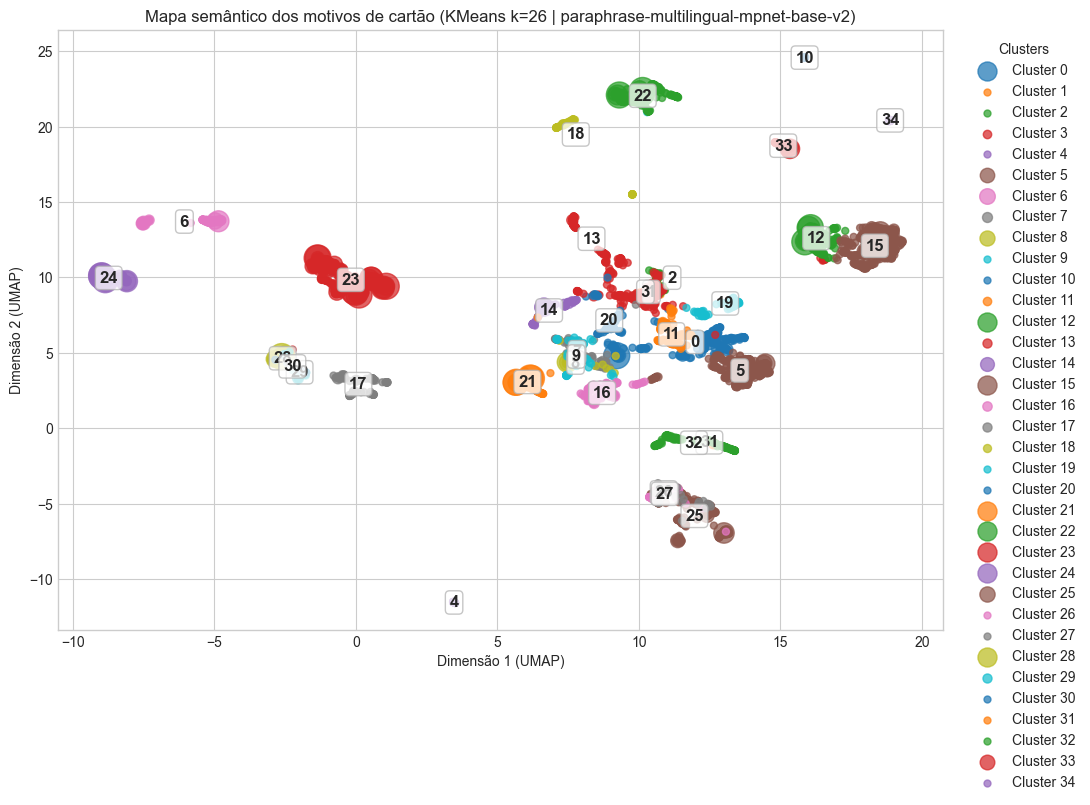

In [83]:
n_neighbors_viz = min(15, len(reason_counts) - 1)
reducer_2d = umap.UMAP(
    n_neighbors=n_neighbors_viz,
    min_dist=0.08,
    metric="cosine",
    random_state=RANDOM_STATE,
)
coords = reducer_2d.fit_transform(embeddings)

reason_counts["x"] = coords[:, 0]
reason_counts["y"] = coords[:, 1]

model_label = MODEL_NAME.split("/")[-1]

fig, ax = plt.subplots(figsize=(11, 8))
for cluster_id, group in reason_counts.groupby("cluster"):
    ax.scatter(
        group["x"], group["y"],
        s=np.clip(group["n_events"] * 6, 25, 350),
        alpha=0.72,
        label=f"Cluster {cluster_id}",
    )
for cluster_id, group in reason_counts.groupby("cluster"):
    centroid = group[["x", "y"]].mean()
    ax.text(
        centroid["x"], centroid["y"],
        str(cluster_id),
        fontsize=12, fontweight="bold", ha="center", va="center",
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.75, "edgecolor": "0.7"},
    )
ax.set_title(f"Mapa semântico dos motivos de cartão (KMeans k={BEST_K} | {model_label})")
ax.set_xlabel("Dimensão 1 (UMAP)")
ax.set_ylabel("Dimensão 2 (UMAP)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Clusters")
plt.tight_layout()
plt.show()

In [84]:
fig_path = OUTPUT_DIR / "card_reason_semantic_map.png"

fig, ax = plt.subplots(figsize=(11, 8))
for cluster_id, group in reason_counts.groupby("cluster"):
    ax.scatter(
        group["x"], group["y"],
        s=np.clip(group["n_events"] * 6, 25, 350),
        alpha=0.72,
        label=f"Cluster {cluster_id}",
    )
for cluster_id, group in reason_counts.groupby("cluster"):
    centroid = group[["x", "y"]].mean()
    ax.text(
        centroid["x"], centroid["y"],
        str(cluster_id),
        fontsize=12, fontweight="bold", ha="center", va="center",
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.75, "edgecolor": "0.7"},
    )
ax.set_title(f"Mapa semântico dos motivos de cartão (KMeans k={BEST_K} | {model_label})")
ax.set_xlabel("Dimensão 1 (UMAP)")
ax.set_ylabel("Dimensão 2 (UMAP)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Clusters")
plt.tight_layout()
fig.savefig(fig_path, dpi=180, bbox_inches="tight")
plt.close(fig)
fig_path

PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_semantic_map.png')

## **9. Leituras por Ano, Time e Árbitro**

A partir daqui, as leituras usam `cluster_group_label`, ou seja, os macrogrupos interpretáveis, não os 30+ clusters finos. Os ids de cluster continuam salvos apenas para auditoria e rastreio.


In [85]:
ANALYSIS_LABEL_COLUMN = "cluster_group_label"

cluster_group_by_year = pd.crosstab(
    reasons_clustered["year"],
    reasons_clustered[ANALYSIS_LABEL_COLUMN],
    normalize="index",
).round(3)

cluster_group_by_year


cluster_group_label,Ataque promissor / falta tática,Ação temerária,Comemoração/entrada em campo,Conduta antidesportiva/regras,Força excessiva / jogo brusco grave,Ofensa direta à arbitragem,Protesto contra arbitragem,Retardar/reiniciar jogo
year,,,,,,,,
2020,0.177,0.524,0.008,0.052,0.039,0.007,0.148,0.045
2021,0.138,0.473,0.022,0.084,0.037,0.006,0.167,0.073
2022,0.160,0.437,0.016,0.099,0.042,0.007,0.172,0.067
2023,0.180,0.416,0.015,0.116,0.028,0.008,0.162,0.075
2024,0.193,0.380,0.019,0.098,0.033,0.004,0.174,0.097
2025,0.201,0.420,0.020,0.114,0.036,0.003,0.138,0.067
2026,0.212,0.407,0.013,0.099,0.030,0.006,0.166,0.067


In [86]:
top_teams = reasons_clustered["team"].value_counts().head(12).index
team_subset = reasons_clustered[reasons_clustered["team"].isin(top_teams)]

cluster_group_by_team = pd.crosstab(
    team_subset["team"],
    team_subset[ANALYSIS_LABEL_COLUMN],
    normalize="index",
).round(3)

cluster_group_by_team


cluster_group_label,Ataque promissor / falta tática,Ação temerária,Comemoração/entrada em campo,Conduta antidesportiva/regras,Força excessiva / jogo brusco grave,Ofensa direta à arbitragem,Protesto contra arbitragem,Retardar/reiniciar jogo
team,,,,,,,,
Athletico Paranaense,0.181,0.427,0.018,0.112,0.037,0.004,0.132,0.088
Atlético Mineiro,0.216,0.423,0.019,0.077,0.041,0.002,0.150,0.071
Corinthians,0.157,0.457,0.025,0.088,0.038,0.008,0.169,0.058
Flamengo,0.186,0.477,0.017,0.097,0.032,0.002,0.140,0.048
Fluminense,0.149,0.448,0.016,0.094,0.025,0.007,0.178,0.082
Fortaleza Esporte Clube,0.176,0.430,0.009,0.090,0.043,0.014,0.165,0.072
Grêmio,0.219,0.369,0.004,0.091,0.035,0.011,0.175,0.095
Internacional,0.162,0.425,0.016,0.092,0.038,0.000,0.178,0.090
Palmeiras,0.193,0.407,0.017,0.099,0.034,0.009,0.184,0.056


In [87]:
top_referees = reasons_clustered["arbitro"].value_counts().head(12).index
referee_subset = reasons_clustered[reasons_clustered["arbitro"].isin(top_referees)]

cluster_group_by_referee = pd.crosstab(
    referee_subset["arbitro"],
    referee_subset[ANALYSIS_LABEL_COLUMN],
    normalize="index",
).round(3)

cluster_group_by_referee


cluster_group_label,Ataque promissor / falta tática,Ação temerária,Comemoração/entrada em campo,Conduta antidesportiva/regras,Força excessiva / jogo brusco grave,Ofensa direta à arbitragem,Protesto contra arbitragem,Retardar/reiniciar jogo
arbitro,,,,,,,,
Anderson Daronco,0.248,0.478,0.010,0.061,0.021,0.004,0.125,0.052
Braulio da Silva Machado,0.107,0.448,0.015,0.107,0.037,0.011,0.211,0.063
Bruno Arleu de Araujo,0.140,0.491,0.012,0.130,0.040,0.003,0.116,0.069
Felipe Fernandes de Lima,0.166,0.425,0.008,0.137,0.032,0.000,0.169,0.063
Flavio Rodrigues de Souza,0.225,0.415,0.030,0.066,0.040,0.008,0.157,0.060
Rafael Rodrigo Klein,0.162,0.410,0.021,0.081,0.039,0.008,0.185,0.094
Ramon Abatti Abel,0.221,0.433,0.018,0.087,0.027,0.005,0.147,0.062
Raphael Claus,0.232,0.513,0.006,0.058,0.041,0.004,0.101,0.046
Rodrigo Jose Pereira de Lima,0.210,0.396,0.016,0.104,0.041,0.000,0.184,0.049


## **10. Busca Semântica de Motivos Parecidos**

Consulta o espaço vetorial com qualquer texto em português. Exemplos:

- `semantic_search("reclamação contra arbitragem")`
- `semantic_search("entrada temerária na disputa de bola")`
- `semantic_search("retardar o reinício do jogo")`
- `semantic_search("conduta violenta")`

In [88]:
def embed_query(text: str) -> np.ndarray:
    return np.asarray(embedding_model.encode([text], normalize_embeddings=True))


def semantic_search(query: str, top_k: int = 10) -> pd.DataFrame:
    query_emb = embed_query(query)
    similarities = cosine_similarity(query_emb, embeddings).ravel()
    result = reason_counts.copy()
    result["similarity"] = similarities

    columns = []
    for optional_column in ["cluster_group_label", "cluster_label"]:
        if optional_column in result.columns:
            columns.append(optional_column)
    columns.extend([
        "similarity", "n_events", "n_yellow", "n_red",
        "reason_category", "reason_detail", "reason",
    ])
    if "cluster" in result.columns:
        columns.append("cluster")
    return result.sort_values("similarity", ascending=False)[columns].head(top_k)


semantic_search("reclamação contra arbitragem", top_k=10)


,cluster_group_label,cluster_label,similarity,n_events,n_yellow,n_red,reason_category,reason_detail,reason,cluster
706,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.969793,2,2,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamação contra as decisoes da arbitragem,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamação contra as decisoes da arbitragem,15
2186,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.966743,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamacao contra arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamacao contra arbitragem.,15
708,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.965386,2,2,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Por reclamação contra à arbitragem.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamação contra à arbitragem.,15
129,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.945632,10,10,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamação contra as decisões da arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamação contra as decisões da arbitragem.,15
2213,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.944300,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamação acintosa contra as decisões da arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamação acintosa contra as decisões da arbitragem.,15
2184,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.930012,1,1,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Por reclamação discordando da decisão da arbitragem.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamação discordando da decisão da arbitragem.,15
2270,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.926986,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamar da arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamar da arbitragem.,15
2185,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.925635,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamação contra as decisões da arbitragem de maneira acintosa.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamação contra as decisões da arbitragem de maneira acintosa.,15
2569,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.925269,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamar de uma decisão da arbitragem de forma acintosa.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamar de uma decisão da arbitragem de forma acintosa.,15
2272,Protesto contra arbitragem,Reclamar/desaprovar decisões da arbitragem,0.917813,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamar da marcação da arbitragem,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamar da marcação da arbitragem,15


## **11. Salvamento dos Artefatos**

In [89]:
reason_counts_path = OUTPUT_DIR / "card_reason_unique_clusters.csv"
reasons_clustered_path = OUTPUT_DIR / "card_reasons_long_with_clusters.csv"
cluster_summary_path = OUTPUT_DIR / "card_reason_cluster_summary.csv"
cluster_group_by_year_path = OUTPUT_DIR / "card_reason_cluster_groups_by_year.csv"
cluster_group_by_team_path = OUTPUT_DIR / "card_reason_cluster_groups_by_team_top12.csv"
cluster_group_by_referee_path = OUTPUT_DIR / "card_reason_cluster_groups_by_referee_top12.csv"

reason_counts.to_csv(reason_counts_path, index=False)
reasons_clustered.to_csv(reasons_clustered_path, index=False)
cluster_summary.to_csv(cluster_summary_path, index=False)
cluster_group_by_year.to_csv(cluster_group_by_year_path)
cluster_group_by_team.to_csv(cluster_group_by_team_path)
cluster_group_by_referee.to_csv(cluster_group_by_referee_path)

print("Arquivos salvos:")
for path in [
    reason_counts_path, reasons_clustered_path, cluster_summary_path,
    cluster_group_by_year_path, cluster_group_by_team_path, cluster_group_by_referee_path,
    fig_path,
]:
    print(f"  {path}")


Arquivos salvos:
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_unique_clusters.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reasons_long_with_clusters.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_cluster_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_cluster_groups_by_year.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_cluster_groups_by_team_top12.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_cluster_groups_by_referee_top12.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_semantic_map.png
